# Experiment 9: Defuzzification Methods (Centroid, Bisector, Mean of Maximum)

**Aim:** To apply and compare basic defuzzification methods such as Centroid, Bisector, and Mean of Maximum using Python.

## Theory
Defuzzification converts a fuzzy output set into a single crisp value.
* **Centroid (COG)**: x* = ∫x·μ(x)dx / ∫μ(x)dx
* **Bisector**: the x that divides the area under μ into two equal parts.
* **Mean of Maximum (MOM)**: average of all x where μ(x) is maximum.
* **Smallest / Largest of Maximum (SOM / LOM)**: smallest / largest x with maximum μ.

### Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
%matplotlib inline

### Step 2: Create an aggregated fuzzy output set

In [2]:
x = np.arange(0, 101, 1)
low    = fuzz.trimf(x, [0, 0, 40])
medium = fuzz.trimf(x, [20, 50, 80])
high   = fuzz.trimf(x, [60, 100, 100])

# Rule strengths -> clipped output sets
a_low  = np.fmin(0.2, low)
a_med  = np.fmin(0.7, medium)
a_high = np.fmin(0.7, high)

# Aggregation (max)
aggregated = np.fmax(a_low, np.fmax(a_med, a_high))

### Step 3: Apply defuzzification methods

In [3]:
methods = ['centroid', 'bisector', 'mom', 'som', 'lom']
results = {m: fuzz.defuzz(x, aggregated, m) for m in methods}
for m, v in results.items():
    print(f"{m.upper():>9} : {v:.3f}")

 CENTROID : 58.791
 BISECTOR : 57.679
      MOM : 67.875
      SOM : 41.000
      LOM : 100.000


### Step 4: Plot the results

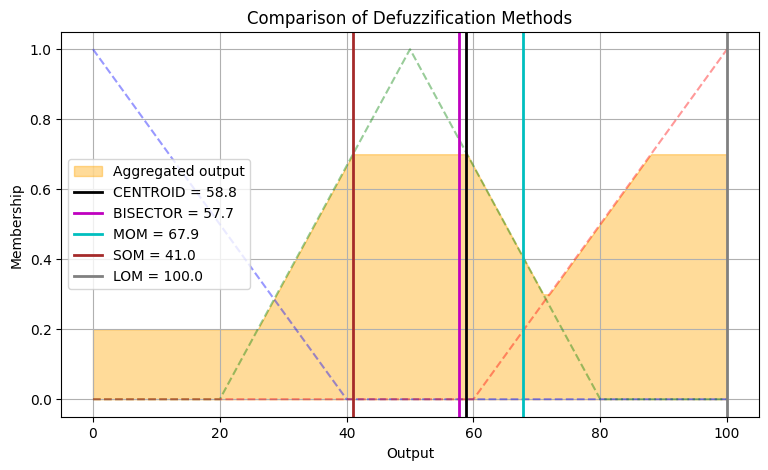

In [4]:
plt.figure(figsize=(9, 5))
plt.plot(x, low, 'b--', alpha=0.4); plt.plot(x, medium, 'g--', alpha=0.4); plt.plot(x, high, 'r--', alpha=0.4)
plt.fill_between(x, aggregated, color='orange', alpha=0.4, label='Aggregated output')
colors = {'centroid': 'k', 'bisector': 'm', 'mom': 'c', 'som': 'brown', 'lom': 'gray'}
for m, v in results.items():
    plt.axvline(v, color=colors[m], lw=2, label=f"{m.upper()} = {v:.1f}")
plt.title('Comparison of Defuzzification Methods'); plt.xlabel('Output'); plt.ylabel('Membership')
plt.legend(); plt.grid(True); plt.show()

### Step 5: Compare in a table

In [5]:
import pandas as pd
pd.DataFrame({'Method': [m.upper() for m in results], 'Crisp Value': [round(v, 3) for v in results.values()]})

,Method,Crisp Value
0,CENTROID,58.791
1,BISECTOR,57.679
2,MOM,67.875
3,SOM,41.000
4,LOM,100.000


### Step 6: Manual implementation (to verify the library)

In [6]:
centroid_manual = np.sum(x * aggregated) / np.sum(aggregated)

# bisector: x where cumulative area = half of total area
cum = np.cumsum(aggregated)
bisector_manual = x[np.argmax(cum >= cum[-1] / 2)]

# mean of maximum
mom_manual = np.mean(x[aggregated == aggregated.max()])

print("Centroid  (manual):", round(centroid_manual, 3), "| skfuzzy:", round(results['centroid'], 3))
print("Bisector  (manual):", bisector_manual,            "| skfuzzy:", round(results['bisector'], 3))
print("MOM       (manual):", round(mom_manual, 3),       "| skfuzzy:", round(results['mom'], 3))

Centroid  (manual): 58.972 | skfuzzy: 58.791
Bisector  (manual): 58 | skfuzzy: 57.679
MOM       (manual): 67.875 | skfuzzy: 67.875


### Step 7: Effect of a different output shape (asymmetric set)

 CENTROID: 59.89
 BISECTOR: 66.67
      MOM: 20.00


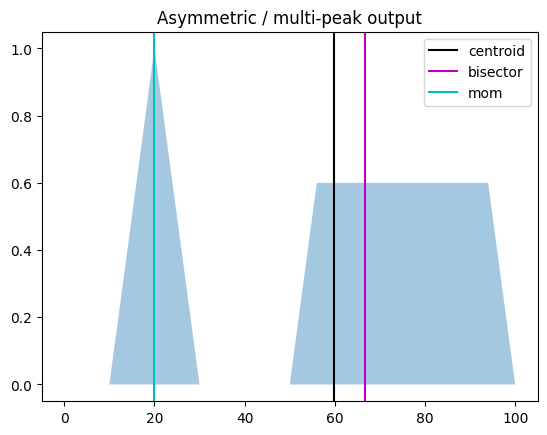

In [7]:
agg2 = np.fmax(np.fmin(1.0, fuzz.trimf(x, [10, 20, 30])), np.fmin(0.6, fuzz.trapmf(x, [50, 60, 90, 100])))
for m in ['centroid', 'bisector', 'mom']:
    print(f"{m.upper():>9}: {fuzz.defuzz(x, agg2, m):.2f}")
plt.fill_between(x, agg2, alpha=0.4)
for m in ['centroid', 'bisector', 'mom']:
    plt.axvline(fuzz.defuzz(x, agg2, m), label=m, color=colors[m])
plt.legend(); plt.title('Asymmetric / multi-peak output'); plt.show()

## Conclusion
Centroid, Bisector and Mean-of-Maximum were applied and compared. Centroid considers the entire shape (most widely used and smooth); bisector splits the area equally; MOM only uses the peak(s) and ignores the rest of the shape.